In [1]:
# we use pandas for handling our dataframes / tables
import pandas as pd

# Prophet is a library from Facebook for time series prediction
from prophet import Prophet

# yfinance accesses yahoo finance to pull stock data
import yfinance as yf

import plotly.graph_objs as go  # Dieser Import löst den NameError 'go'
from prophet.plot import plot_plotly, plot_components_plotly


/workspaces/HandOnML1/tutorial_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# we define our stockname here, change it here to apply to a different stock, eg. to "MSFT"
# this will also be used to dynamically label our output
stockname = "TSLA"

# this gives us a timestamp
import datetime as dt
# we will also use this later to dynamically name our output files
time = dt.datetime.today().strftime("%Y%m%d")

# we call yahoo finance to get information about our stock
stock = yf.Ticker(stockname)

# get stock info
stock.info

{'address1': '1 Tesla Road',
 'city': 'Austin',
 'state': 'TX',
 'zip': '78725',
 'country': 'United States',
 'phone': '512 516 8177',
 'website': 'https://www.tesla.com',
 'industry': 'Auto Manufacturers',
 'industryKey': 'auto-manufacturers',
 'industryDisp': 'Auto Manufacturers',
 'sector': 'Consumer Cyclical',
 'sectorKey': 'consumer-cyclical',
 'sectorDisp': 'Consumer Cyclical',
 'longBusinessSummary': 'Tesla, Inc. designs, develops, manufactures, leases, and sells electric vehicles, and energy generation and storage systems in the United States, China, and internationally. The company operates in two segments, Automotive; and Energy Generation and Storage. The company offers electric vehicles, as well as sells automotive regulatory credits; and non-warranty maintenance services and collision, automotive insurance services, as well as part sales and retail merchandise sale. It also provides sedans and sport utility vehicles through direct and used vehicle sales, a network of Tesl

In [3]:
# get historical market data
hist = stock.history(period="max", auto_adjust=True)

# show the head of the dataframe we just downloaded
# we do this by using head() on the dataframe.
# This also shows us the earliest data points
hist.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [4]:
# this shows us some quick statistics
hist.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,3934.000000,3934.000000,3934.000000,3934.000000,3.934000e+03,3934.0,3934.000000
mean,101.884773,104.094699,99.523764,101.854456,9.646330e+07,0.0,0.002034
std,128.375344,131.106196,125.381743,128.274135,7.546689e+07,0.0,0.092955
min,1.076000,1.108667,0.998667,1.053333,1.777500e+06,0.0,0.000000
25%,12.834333,13.052667,12.616333,12.872500,5.149462e+07,0.0,0.000000
50%,20.060000,20.437333,19.683333,20.069334,8.279025e+07,0.0,0.000000
75%,210.597504,216.536663,206.317497,211.717503,1.207078e+08,0.0,0.000000
max,489.880005,498.829987,485.329987,489.880005,9.140820e+08,0.0,5.000000


In [5]:
# we want out input table to have 2 columns, ds and y, so let’s just copy the historical dates (hist.index) and adjusted closing prices (hist[‘Close’]) to a new DataFrame.

# we're creating a new DataFrame
df = pd.DataFrame()

# We create a column called "ds" in the new data frame and fill it with the index from hist (this is the data)
df['ds'] = hist.index.values

# We also create a column called y, this is filled with the Close value from hist
df['y'] = hist['Close'].values
# just as we used heads before to look at the beginning of a Dataframe, we can use tail to look at the last values
df.tail()

,ds,y
3929,2026-02-11 05:00:00,428.269989
3930,2026-02-12 05:00:00,417.070007
3931,2026-02-13 05:00:00,417.440002
3932,2026-02-17 05:00:00,410.630005
3933,2026-02-18 05:00:00,411.320007


In [6]:
# This calls Prophet
m = Prophet( )

# we are now using Prophet to learn past time series
m.fit(df)

10:26:28 - cmdstanpy - INFO - Chain [1] start processing
10:26:30 - cmdstanpy - INFO - Chain [1] done processing


In [7]:
# lets "create the future" aka create a dataframe for it
# we want to forecast 365 periods into the future, prohpet automatically understands that our dates are days
future = m.make_future_dataframe(periods=365)

# right now our dataframe is empty and just shows future dates. let's see if it counted correctly, by looking at the last values
future.tail()

,ds
4294,2027-02-14 05:00:00
4295,2027-02-15 05:00:00
4296,2027-02-16 05:00:00
4297,2027-02-17 05:00:00
4298,2027-02-18 05:00:00


In [8]:
# now we use predict to fill our new dataframe with the values
forecast = m.predict(future)

# we also filter the columns along the way, because Prophet gives you a lot more output to work with
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
4294,2027-02-14 05:00:00,447.480147,396.125972,498.150206
4295,2027-02-15 05:00:00,468.549629,417.288240,519.953722
4296,2027-02-16 05:00:00,467.392909,414.643053,516.233324
4297,2027-02-17 05:00:00,467.320229,415.620118,516.532443
4298,2027-02-18 05:00:00,465.998666,414.592399,519.344124


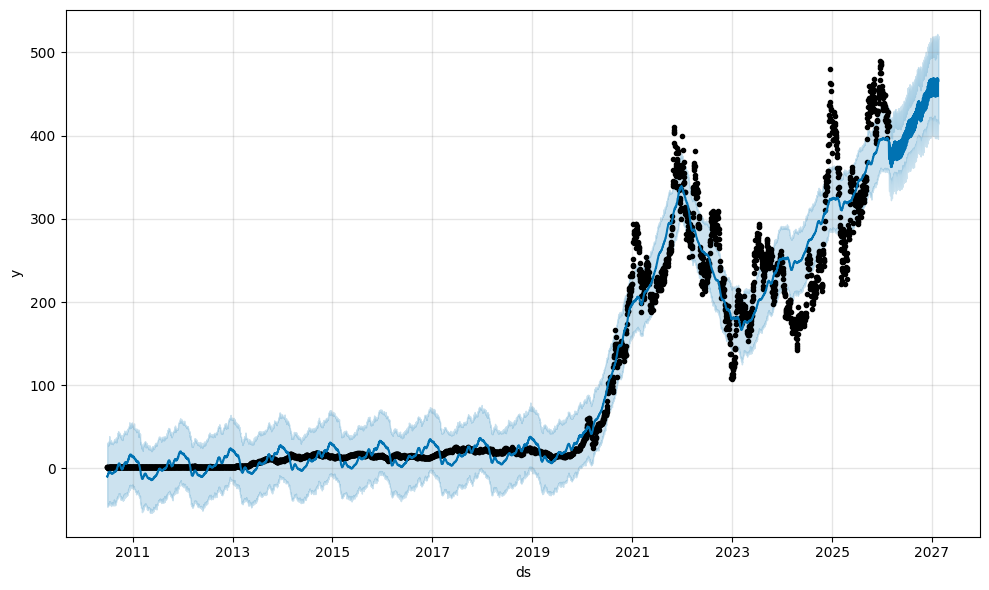

In [9]:
# if we just want an image, we can use this command
fig1 = m.plot(forecast)

In [10]:
import plotly.graph_objs as go
import prophet.plot
import plotly.io as pio

# 1. Den Bug in Prophet beheben
prophet.plot.go = go

# 2. Den Renderer für VS Code sicherheitshalber explizit setzen
pio.renderers.default = "vscode" 

# 3. Plot erstellen und anzeigen
fig = plot_plotly(m, forecast)
fig.show()


In [11]:
# we can also have a component analysis, e.g. seasonality within a year or a week
plot_components_plotly(m, forecast)